# Análise Exploratória

## Objetivo
Visualizar preços e retornos ao longo do tempo; calcular estatísticas descritivas; observar tendências, lacunas e possíveis mudanças de comportamento.

## 1. Pergunta de pesquisa
* Fazer uma análise exploratória a partir dos métodos que estão sendo desenvolvidos.*

## 6. Validação e limitações
Verificar consistência, dados ausentes, sensibilidade aos parâmetros e limitações do método.
##

Esta etapa tem como objetivo investigar as características estatísticas e temporais dos dados históricos do Ibovespa, buscando compreender o comportamento dos preços e dos retornos financeiros.

Além da exploração visual e estatística, será realizada uma avaliação crítica da qualidade dos dados e das escolhas metodológicas utilizadas.

A análise será dividida em quatro aspectos principais:

- **Consistência:** verificar a integridade dos registros, a sequência temporal e a coerência dos valores calculados.
- **Dados ausentes:** identificar possíveis lacunas e avaliar como elas podem afetar as análises.
- **Sensibilidade aos parâmetros:** investigar como diferentes escolhas de frequência, janelas temporais e estimadores alteram os resultados.
- **Limitações metodológicas:** identificar quais conclusões são sustentadas pelos dados e quais exigiriam análises adicionais.

O propósito não é apenas descrever o comportamento histórico do Ibovespa, mas também avaliar a confiabilidade das evidências encontradas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

raiz_projeto = Path.cwd()

if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

arquivo = raiz_projeto / "data" / "processed" / "ibovespa_tratado.csv"

dados = pd.read_csv(
    arquivo,
    index_col="Data",
    parse_dates=True
)

dados = dados.sort_index()

display(dados.head())
display(dados.tail())

print("Dimensões:", dados.shape)
print("\nPeríodo analisado:")
print("Início:", dados.index.min())
print("Fim:", dados.index.max())

,Preco_Fechamento,Retorno_Simples,Retorno_Log
Data,,,
2015-01-05,47517.0,-0.020510,-0.020724
2015-01-06,48001.0,0.010186,0.010134
2015-01-07,49463.0,0.030458,0.030003
2015-01-08,49943.0,0.009704,0.009657
2015-01-09,48840.0,-0.022085,-0.022333


,Preco_Fechamento,Retorno_Simples,Retorno_Log
Data,,,
2026-11-09,172236.0,0.022178,0.021936
2026-11-10,171337.0,-0.005220,-0.005233
2026-11-11,172060.0,0.004220,0.004211
2026-11-12,171324.0,-0.004278,-0.004287
2026-11-13,172458.0,0.006619,0.006597


Dimensões: (2945, 3)

Período analisado:
Início: 2015-01-05 00:00:00
Fim: 2026-11-13 00:00:00


In [2]:
print("Tipos de dados:")
print(dados.dtypes)

print("\nValores ausentes:")
print(dados.isna().sum())

print("\nDatas duplicadas:")
print(dados.index.duplicated().sum())

print("\nPreços iguais ou inferiores a zero:")
print((dados["Preco_Fechamento"] <= 0).sum())

print("\nEstatísticas descritivas:")
display(dados.describe())

Tipos de dados:
Preco_Fechamento    float64
Retorno_Simples     float64
Retorno_Log         float64
dtype: object

Valores ausentes:
Preco_Fechamento    0
Retorno_Simples     0
Retorno_Log         0
dtype: int64

Datas duplicadas:
0

Preços iguais ou inferiores a zero:
0

Estatísticas descritivas:


,Preco_Fechamento,Retorno_Simples,Retorno_Log
count,2945.000000,2945.000000,2945.000000
mean,102589.824788,0.000541,0.000431
std,35733.595040,0.014775,0.014888
min,37497.000000,-0.147797,-0.159930
25%,74443.000000,-0.006976,-0.007000
50%,105146.000000,0.000496,0.000496
75%,124196.000000,0.008260,0.008226
max,209067.000000,0.139082,0.130223


In [3]:
retorno_simples = (
    dados["Preco_Fechamento"].pct_change()
)

retorno_log = np.log(
    dados["Preco_Fechamento"] /
    dados["Preco_Fechamento"].shift(1)
)

print(
    "Retorno simples consistente:",
    np.allclose(
        dados["Retorno_Simples"].iloc[1:],
        retorno_simples.iloc[1:],
        equal_nan=True
    )
)

print(
    "Retorno logarítmico consistente:",
    np.allclose(
        dados["Retorno_Log"].iloc[1:],
        retorno_log.iloc[1:],
        equal_nan=True
    )
)

Retorno simples consistente: True
Retorno logarítmico consistente: True


In [4]:
print("Quantidade de valores ausentes por coluna:")
print(dados.isna().sum())

print("\nIntervalos entre observações:")
intervalos = dados.index.to_series().diff().dt.days

display(intervalos.value_counts().sort_index())

Quantidade de valores ausentes por coluna:
Preco_Fechamento    0
Retorno_Simples     0
Retorno_Log         0
dtype: int64

Intervalos entre observações:


Data
1.0    2270
2.0      50
3.0     556
4.0      48
5.0      20
Name: count, dtype: int64

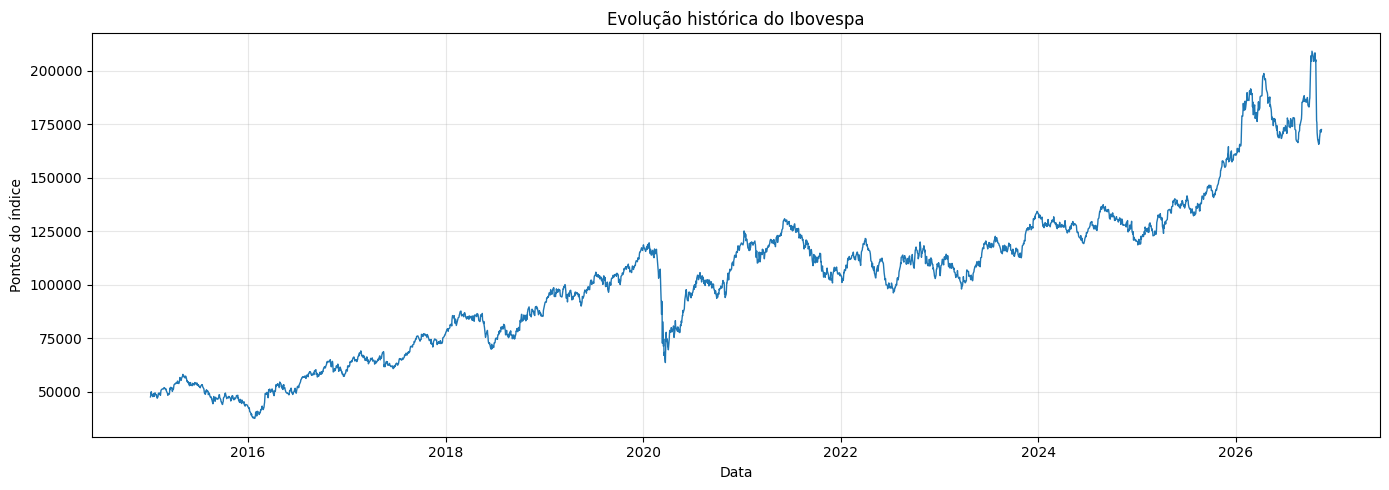

In [5]:
plt.figure(figsize=(14, 5))

plt.plot(
    dados.index,
    dados["Preco_Fechamento"],
    linewidth=1
)

plt.title("Evolução histórica do Ibovespa")
plt.xlabel("Data")
plt.ylabel("Pontos do índice")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

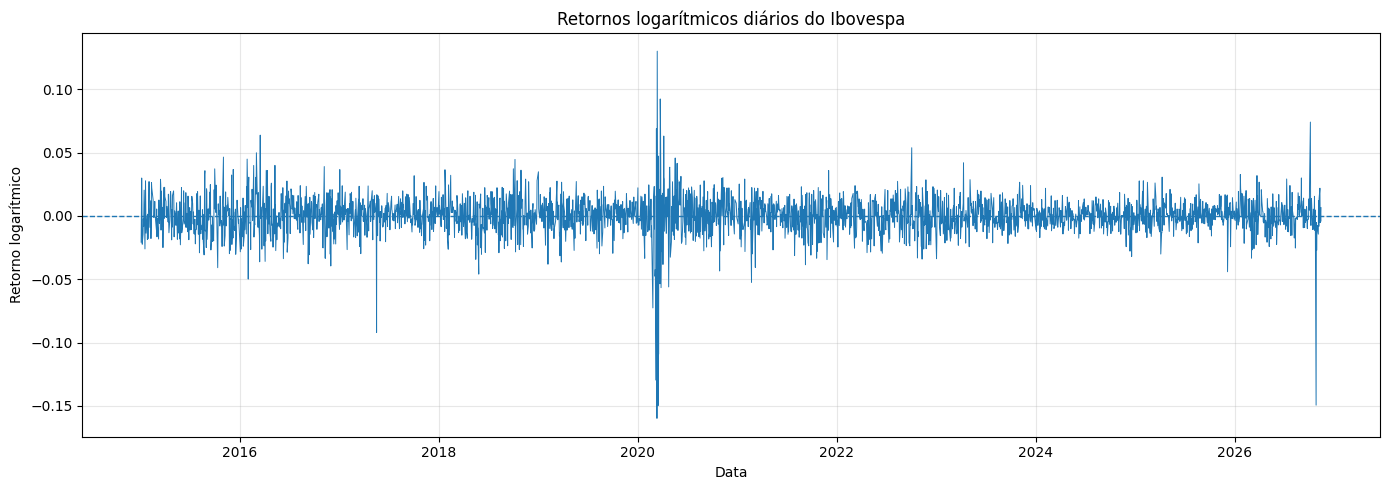

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    dados.index,
    dados["Retorno_Log"],
    linewidth=0.7
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Retornos logarítmicos diários do Ibovespa")
plt.xlabel("Data")
plt.ylabel("Retorno logarítmico")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
retornos = dados["Retorno_Log"]

volatilidade = pd.DataFrame({
    "20_pregoes": retornos.rolling(20).std(),
    "60_pregoes": retornos.rolling(60).std(),
    "252_pregoes": retornos.rolling(252).std()
})

# Anualização usando aproximadamente 252 pregões por ano
volatilidade_anualizada = volatilidade * np.sqrt(252)

display(volatilidade_anualizada.tail())

,20_pregoes,60_pregoes,252_pregoes
Data,,,
2026-11-09,0.560308,0.384529,0.247982
2026-11-10,0.554123,0.384665,0.247987
2026-11-11,0.556387,0.384731,0.248012
2026-11-12,0.556025,0.384846,0.247502
2026-11-13,0.558851,0.384993,0.247579


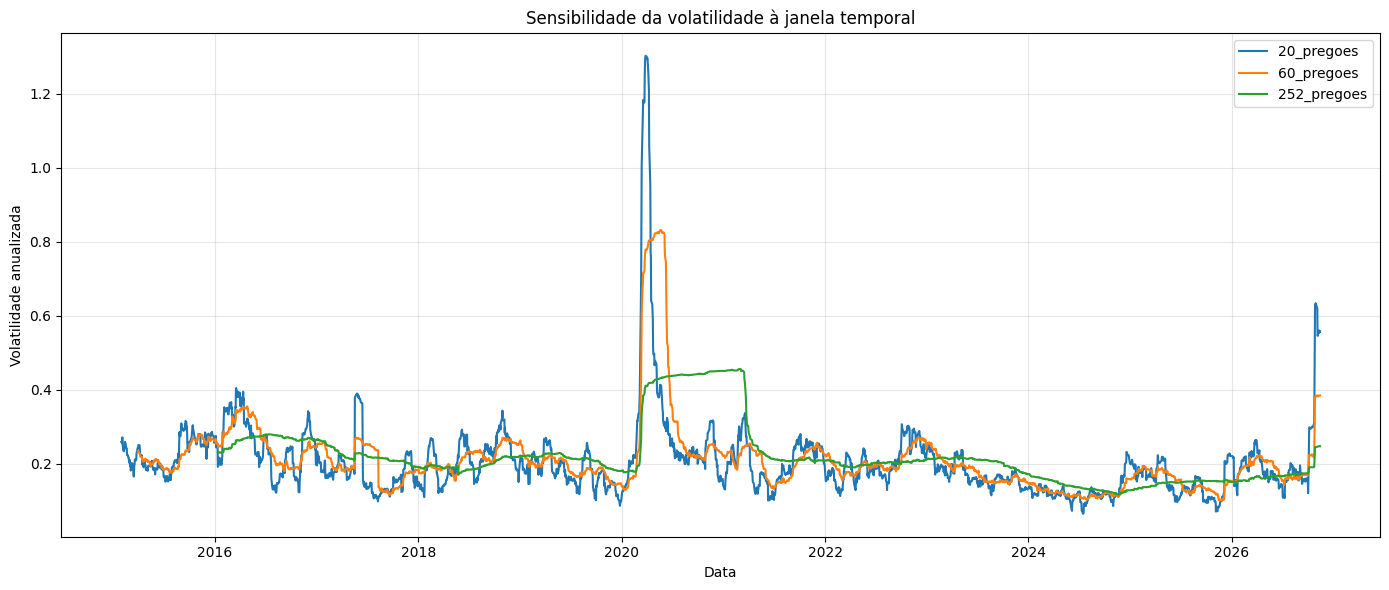

In [8]:
plt.figure(figsize=(14, 6))

for coluna in volatilidade_anualizada.columns:
    plt.plot(
        volatilidade_anualizada.index,
        volatilidade_anualizada[coluna],
        label=coluna
    )

plt.title("Sensibilidade da volatilidade à janela temporal")
plt.xlabel("Data")
plt.ylabel("Volatilidade anualizada")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Limitações metodológicas

A análise exploratória utiliza dados históricos do Ibovespa e indicadores estatísticos calculados a partir dos retornos diários. Embora esses procedimentos permitam identificar características importantes da série temporal, existem limitações que precisam ser consideradas.

1. **Dependência histórica:** os padrões identificados no passado não garantem que o comportamento futuro será semelhante.

2. **Frequência dos dados:** a utilização de observações diárias não permite identificar todas as oscilações que ocorrem em intervalos menores, como minutos ou segundos.

3. **Sensibilidade às janelas temporais:** medidas como volatilidade dependem do intervalo utilizado no cálculo e podem apresentar resultados diferentes conforme o parâmetro escolhido.

4. **Eventos extremos:** observações muito distantes da média podem influenciar significativamente medidas estatísticas, como variância e desvio-padrão.

5. **Distribuição dos retornos:** a utilização de modelos normais como referência não significa que os retornos financeiros sigam necessariamente uma distribuição normal.

6. **Ausência de causalidade:** a análise estatística permite identificar associações e padrões, mas não estabelece, isoladamente, as causas das variações observadas.

7. **Limitações da fonte:** a análise depende da disponibilidade, precisão e metodologia de atualização dos dados fornecidos pela fonte utilizada.

Portanto, os resultados devem ser interpretados como evidências estatísticas sobre o comportamento histórico da série, e não como previsões ou explicações definitivas do mercado.